# 02 — Baseline pipeline on the Studio GPU
First a short PILOT (3 epochs, BCE) to time the GPU; then the full-budget BCE baseline (50 epochs) only when you choose to run it. Checkpoint/threshold selected on **validation only**. The `--seed` and config are recorded in `run_meta.json`.

In [1]:
import os, json, subprocess, sys
HOME=os.path.expanduser('~'); ROOT=f'{HOME}/brain-mri-segmentation'; PROJ=ROOT; DATA=f'{ROOT}/data'; RUNS=f'{ROOT}/runs'
os.chdir(ROOT)
sys.path.insert(0, f'{PROJ}/src')
print(open(f'{PROJ}/configs/pilot_bce_3ep.yaml').read())

# Shared budget: identical for every condition (fairness)
seed: 0
base_channels: 32
batch_size: 16
epochs: 3
lr: 0.001
weight_decay: 0.0001
workers: 4
selection_metric: pooled_foreground_dice   # val-only, same rule for all conditions
threshold_grid: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
name: PILOT_bce_3ep
loss: bce
# PILOT ONLY: runtime/throughput check, not a research result



In [2]:
!cd ~/brain-mri-segmentation && python scripts/eval_reference.py --data-root ~/brain-mri-segmentation/data --out ~/brain-mri-segmentation/evidence/always_empty_val.json

{
  "n_slices": 598,
  "pooled_foreground_dice": 0.0,
  "pooled_foreground_iou": 0.0,
  "mean_slice_dice": 0.6588628762541806,
  "mean_slice_iou": 0.6588628762541806,
  "positive_slice_dice": 0.0,
  "positive_slice_iou": 0.0,
  "n_positive": 204,
  "n_empty": 394,
  "empty_slices_with_fp": 0,
  "empty_fp_rate": 0.0,
  "empty_fp_pixels_total": 0,
  "empty_fp_pixels_mean": 0.0,
  "patient_dice_mean": 0.0,
  "patient_dice_median": 0.0,
  "patient_dice_std": 0.0,
  "patient_dice_min": 0.0,
  "n_patients": 17
}


In [3]:
!cd ~/brain-mri-segmentation && python scripts/train.py --config configs/pilot_bce_3ep.yaml --data-root ~/brain-mri-segmentation/data --out-root ~/brain-mri-segmentation/runs/studio_pilot --seed 0

{"epoch": 0, "loss": 0.29004399430436845, "pooled_foreground_dice": 0.2973988527598856, "empty_fp": 48}
{"epoch": 1, "loss": 0.08233431750693444, "pooled_foreground_dice": 0.43936162633291376, "empty_fp": 27}
{"epoch": 2, "loss": 0.05113349448845001, "pooled_foreground_dice": 0.6092368833588807, "empty_fp": 29}
VAL (selected thr) 0.30 {"n_slices": 598, "pooled_foreground_dice": 0.6287159190127304, "pooled_foreground_iou": 0.4584869960424831, "mean_slice_dice": 0.6991801800720119, "mean_slice_iou": 0.6689449847621276, "positive_slice_dice": 0.44171444942677984, "positive_slice_iou": 0.35308382788113846, "n_positive": 204, "n_empty": 394, "empty_slices_with_fp": 66, "empty_fp_rate": 0.16751269035532995, "empty_fp_pixels_total": 32693, "empty_fp_pixels_mean": 82.9771573604061, "patient_dice_mean": 0.5143097314519175, "patient_dice_median": 0.5744693692787446, "patient_dice_std": 0.3010848428981673, "patient_dice_min": 0.0, "n_patients": 17}


In [4]:
m=json.load(open(f'{RUNS}/studio_pilot/PILOT_bce_3ep_s0/run_meta.json')); print(m['gpu'], round(m['train_time_s'],1),'s'); print(json.dumps(m['val_at_selected'],indent=1))

NVIDIA L40S 40.7 s
{
 "n_slices": 598,
 "pooled_foreground_dice": 0.6287159190127304,
 "pooled_foreground_iou": 0.4584869960424831,
 "mean_slice_dice": 0.6991801800720119,
 "mean_slice_iou": 0.6689449847621276,
 "positive_slice_dice": 0.44171444942677984,
 "positive_slice_iou": 0.35308382788113846,
 "n_positive": 204,
 "n_empty": 394,
 "empty_slices_with_fp": 66,
 "empty_fp_rate": 0.16751269035532995,
 "empty_fp_pixels_total": 32693,
 "empty_fp_pixels_mean": 82.9771573604061,
 "patient_dice_mean": 0.5143097314519175,
 "patient_dice_median": 0.5744693692787446,
 "patient_dice_std": 0.3010848428981673,
 "patient_dice_min": 0.0,
 "n_patients": 17
}


## Full-budget learned baseline (run deliberately)
Uncomment to run 50-epoch BCE baseline, seed 0 (~11 min estimated on L40S from the managed pilot; not yet measured here).

In [ ]:
# !cd ~/brain-mri-segmentation && python scripts/train.py --config configs/bce_baseline.yaml --data-root ~/brain-mri-segmentation/data --out-root ~/brain-mri-segmentation/runs/study --seed 0

## Validation-only analysis for any finished run: overlays + lesion-size subgroup
Size tertile boundaries are computed on **training** positive slices only. Set `RUN` to the run directory to analyse.

In [5]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from lggseg.data import read_image, read_mask
from lggseg.model import UNet
from lggseg.metrics import slice_records, summarize
RUN=f'{RUNS}/studio_pilot/PILOT_bce_3ep_s0'
meta=json.load(open(f'{RUN}/run_meta.json')); st=json.load(open(f'{RUN}/channel_stats.json'))
m=UNet(base=meta['config']['base_channels']).cuda().eval(); m.load_state_dict(torch.load(f'{RUN}/best.pt'))
va=pd.read_csv(f'{DATA}/val_manifest.csv'); mean=np.array(st['mean'],np.float32); sd=np.array(st['std'],np.float32)
P=[]
with torch.no_grad():
    for i in range(0,len(va),32):
        x=np.stack([((read_image(f'{DATA}/'+q)-mean)/sd).transpose(2,0,1) for q in va.image_path[i:i+32]]).astype(np.float32)
        P.append(torch.sigmoid(m(torch.from_numpy(x).cuda())).cpu().numpy()[:,0])
P=np.concatenate(P)>=meta['selected_threshold']; G=np.stack([read_mask(f'{DATA}/'+q) for q in va.mask_path])
sr=slice_records(P,G,va.patient_id,va.slice_id); print(json.dumps(summarize(sr),indent=1))

{
 "n_slices": 598,
 "pooled_foreground_dice": 0.6287138353880939,
 "pooled_foreground_iou": 0.4584847799190252,
 "mean_slice_dice": 0.6991805497279223,
 "mean_slice_iou": 0.6689457450762692,
 "positive_slice_dice": 0.4417155330259686,
 "positive_slice_iou": 0.35308605664514253,
 "n_positive": 204,
 "n_empty": 394,
 "empty_slices_with_fp": 66,
 "empty_fp_rate": 0.16751269035532995,
 "empty_fp_pixels_total": 32695,
 "empty_fp_pixels_mean": 82.98223350253807,
 "patient_dice_mean": 0.514313694222363,
 "patient_dice_median": 0.5744693692787446,
 "patient_dice_std": 0.30110146981172803,
 "patient_dice_min": 0.0,
 "n_patients": 17
}


In [6]:
tr=pd.read_csv(f'{DATA}/train_manifest.csv'); b=tr[tr.has_foreground==1].foreground_pixels.quantile([1/3,2/3]).values
pos=sr[sr.gt_empty==0].copy(); pos['size_group']=pd.cut(pos.gt_pixels,[0,b[0],b[1],np.inf],labels=['small','medium','large'])
print('train-derived boundaries',b); print(pos.groupby('size_group',observed=True).dice.agg(['count','mean','median']))
print(sr.groupby('patient_id').apply(lambda d: 2*d.tp.sum()/max(1,2*d.tp.sum()+d.fp.sum()+d.fn.sum()),include_groups=False).describe())

train-derived boundaries [1038.         2350.66666667]
            count      mean    median
size_group                           
small          92  0.248549  0.000000
medium         65  0.552307  0.644649
large          47  0.666883  0.751424
count    17.000000
mean      0.514314
std       0.301101
min       0.000000
25%       0.370040
50%       0.574469
75%       0.772900
max       0.890784
dtype: float64


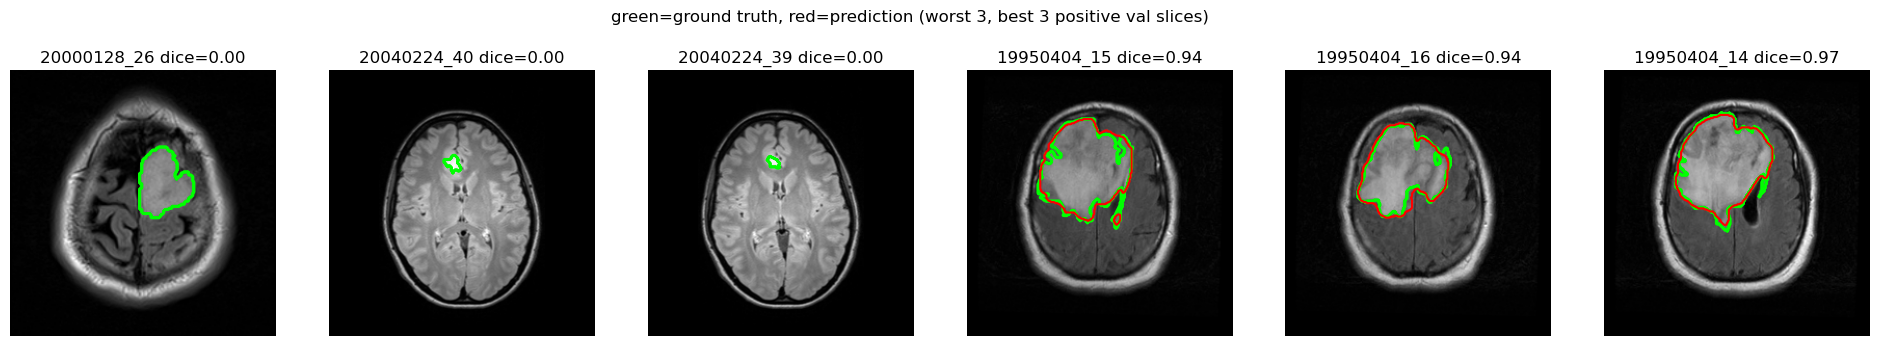

In [7]:
idx=list(pos.sort_values('dice').index[:3])+list(pos.sort_values('dice').index[-3:])
fig,ax=plt.subplots(1,6,figsize=(24,4))
for a,i in zip(ax,idx):
    a.imshow(read_image(f'{DATA}/'+va.image_path[i])[...,1],cmap='gray'); a.contour(G[i],colors='lime'); a.contour(P[i],colors='r'); a.set_title(f"{va.slice_id[i]} dice={sr.dice[i]:.2f}"); a.axis('off')
plt.suptitle('green=ground truth, red=prediction (worst 3, best 3 positive val slices)'); plt.show()

In [8]:
# Full-budget BCE baseline only: launch detached so the notebook remains usable.
# Config is asserted below; outputs go to the distinct config-derived run directory.
import os, sys, subprocess, datetime, glob, yaml
from lggseg.model import UNet
ROOT=os.path.expanduser('~/brain-mri-segmentation')
RUNS=os.path.join(ROOT,'runs','study')
RUN_DIR=os.path.join(RUNS,'bce_baseline_s0')
CONFIG=os.path.join(ROOT,'configs','bce_baseline.yaml')
cfg=yaml.safe_load(open(CONFIG))
assert cfg['name']=='bce_baseline' and cfg['seed']==0 and cfg['epochs']==50 and cfg['loss']=='bce', f'Unexpected baseline config: {cfg}'
params=sum(p.numel() for p in UNet(base=int(cfg['base_channels'])).parameters())
print('CONFIG',cfg)
print('MODEL_PARAMETERS',params)
print('RUN_DIR',RUN_DIR)
assert not os.path.exists(RUN_DIR), f'Refusing to overwrite existing run: {RUN_DIR}'
active=[]
for f in glob.glob('/proc/[0-9]*/cmdline'):
    try:
        pid=int(f.split('/')[2])
        argv=open(f,'rb').read().split(b'\0')
        if pid!=os.getpid() and b'scripts/train.py' in argv and b'configs/bce_baseline.yaml' in argv:
            active.append(pid)
    except (FileNotFoundError,ProcessLookupError):
        pass
assert not active, f'Baseline training process already exists: {active}'
os.makedirs(RUNS,exist_ok=True)
LOG=os.path.join(RUNS,'bce_baseline_s0-stdout.log')
with open(LOG,'ab',buffering=0) as out:
    proc=subprocess.Popen([sys.executable,'scripts/train.py','--config','configs/bce_baseline.yaml','--data-root',os.path.join(ROOT,'data'),'--out-root',RUNS,'--seed','0'],cwd=ROOT,stdout=out,stderr=subprocess.STDOUT,stdin=subprocess.DEVNULL,start_new_session=True)
print('LAUNCHED_UTC',datetime.datetime.now(datetime.timezone.utc).isoformat())
print('PID',proc.pid)
print('STDOUT_LOG',LOG)

CONFIG {'seed': 0, 'base_channels': 32, 'batch_size': 16, 'epochs': 50, 'lr': 0.001, 'weight_decay': 0.0001, 'workers': 4, 'selection_metric': 'pooled_foreground_dice', 'threshold_grid': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], 'name': 'bce_baseline', 'loss': 'bce'}
MODEL_PARAMETERS 7763041
RUN_DIR /home/sagemaker-user/brain-mri-segmentation/runs/study/bce_baseline_s0
LAUNCHED_UTC 2026-11-08T10:00:28.516890+00:00
PID 32926
STDOUT_LOG /home/sagemaker-user/brain-mri-segmentation/runs/study/bce_baseline_s0-stdout.log


In [9]:
# One-shot read-only status check for the already-launched preliminary BCE baseline.
from pathlib import Path
from datetime import datetime, timezone
import json, re
PID=32926
ROOT=Path.home()/'brain-mri-segmentation'
RUN=ROOT/'runs/study/bce_baseline_s0'
STDOUT=ROOT/'runs/study/bce_baseline_s0-stdout.log'
print('SNAPSHOT_UTC',datetime.now(timezone.utc).isoformat())
proc=Path('/proc')/str(PID)
print('PID_ALIVE',proc.exists())
if proc.exists():
    try:
        argv=[x.decode(errors='replace') for x in (proc/'cmdline').read_bytes().split(bytes([0])) if x]
        state=next((x for x in (proc/'status').read_text().splitlines() if x.startswith('State:')),'unknown')
        print('PID_STATE',state)
        print('PID_CMDLINE',' '.join(argv))
    except (FileNotFoundError,ProcessLookupError) as e:
        print('PID_STATUS_READ',type(e).__name__)
print('RUN_DIR_EXISTS',RUN.exists())
runfiles=sorted([p for p in RUN.iterdir() if p.is_file()]) if RUN.exists() else []
print('RUN_FILES',[(p.name,p.stat().st_size,datetime.fromtimestamp(p.stat().st_mtime,timezone.utc).isoformat()) for p in runfiles])
checkpoints=[p for p in runfiles if p.suffix.lower() in {'.pt','.pth','.ckpt'}]
print('CHECKPOINTS',[(p.name,p.stat().st_size) for p in checkpoints])
raw=STDOUT.read_text(errors='replace') if STDOUT.exists() else ''
lines=raw.splitlines()
print('STDOUT_EXISTS',STDOUT.exists(),'BYTES',len(raw),'MTIME_UTC',datetime.fromtimestamp(STDOUT.stat().st_mtime,timezone.utc).isoformat() if STDOUT.exists() else None)
print('STDOUT_EPOCH_LINES',[x for x in lines if re.search(r'epoch',x,re.I)])
print('STDOUT_ERRORS',[x for x in lines if re.search(r'traceback|error|exception|runtimeerror|cuda error',x,re.I)])
trainlog=RUN/'train_log.json'
print('TRAIN_LOG_EXISTS',trainlog.exists())
if trainlog.exists():
    txt=trainlog.read_text(errors='replace')
    print('TRAIN_LOG_BYTES',len(txt),'MTIME_UTC',datetime.fromtimestamp(trainlog.stat().st_mtime,timezone.utc).isoformat())
    try:
        obj=json.loads(txt); epochs=[]
        def walk(x):
            if isinstance(x,dict):
                if isinstance(x.get('epoch'),(int,float)): epochs.append(x['epoch'])
                for v in x.values(): walk(v)
            elif isinstance(x,list):
                for v in x: walk(v)
        walk(obj)
        print('TRAIN_LOG_EPOCH_INDICES',sorted(set(epochs)))
        print('TRAIN_LOG_SUMMARY',obj if isinstance(obj,dict) and not epochs else 'epoch records parsed')
    except Exception as e:
        print('TRAIN_LOG_PARSE',type(e).__name__,str(e))

SNAPSHOT_UTC 2026-11-08T10:03:16.261584+00:00
PID_ALIVE True
PID_STATE State:	R (running)
PID_CMDLINE /opt/conda/bin/python scripts/train.py --config configs/bce_baseline.yaml --data-root /home/sagemaker-user/brain-mri-segmentation/data --out-root /home/sagemaker-user/brain-mri-segmentation/runs/study --seed 0
RUN_DIR_EXISTS True
RUN_FILES [('best.pt', 31107871, '2026-11-08T10:02:20.543256+00:00'), ('channel_stats.json', 219, '2026-11-08T10:00:37.378587+00:00')]
CHECKPOINTS [('best.pt', 31107871)]
STDOUT_EXISTS True BYTES 1258 MTIME_UTC 2026-11-08T10:03:10.885559+00:00
STDOUT_EPOCH_LINES ['{"epoch": 0, "loss": 0.2915473190977916, "pooled_foreground_dice": 0.26637164810702396, "empty_fp": 15}', '{"epoch": 1, "loss": 0.07369263449139755, "pooled_foreground_dice": 0.4943536273243607, "empty_fp": 55}', '{"epoch": 2, "loss": 0.0412230567249577, "pooled_foreground_dice": 0.49465577727691024, "empty_fp": 168}', '{"epoch": 3, "loss": 0.029851952002094225, "pooled_foreground_dice": 0.6244198586

In [10]:
# One-shot read-only status for preliminary BCE baseline PID 32926.
from pathlib import Path
from datetime import datetime, timezone
import json, re
PID=32926
ROOT=Path.home()/'brain-mri-segmentation'
RUN=ROOT/'runs/study/bce_baseline_s0'
BASE=ROOT/'runs/study'
STDOUT=BASE/'bce_baseline_s0-stdout.log'
META=RUN/'run_meta.json'
print('SNAPSHOT_UTC',datetime.now(timezone.utc).isoformat())
proc=Path('/proc')/str(PID)
print('PID_ALIVE',proc.exists())
if proc.exists():
    try:
        argv=[x.decode(errors='replace') for x in (proc/'cmdline').read_bytes().split(bytes([0])) if x]
        state=next((x for x in (proc/'status').read_text().splitlines() if x.startswith('State:')),'unknown')
        print('PID_STATE',state)
        print('PID_CMDLINE',' '.join(argv))
    except (FileNotFoundError,ProcessLookupError) as e:
        print('PID_STATUS_READ',type(e).__name__)
print('RUN_DIR_EXISTS',RUN.exists())
files=sorted([p for p in RUN.iterdir() if p.is_file()]) if RUN.exists() else []
print('RUN_FILES',[(p.name,p.stat().st_size,datetime.fromtimestamp(p.stat().st_mtime,timezone.utc).isoformat()) for p in files])
print('CHECKPOINTS',[(p.name,p.stat().st_size) for p in files if p.suffix.lower() in {'.pt','.pth','.ckpt'}])
raw=STDOUT.read_text(errors='replace') if STDOUT.exists() else ''
lines=raw.splitlines(); records=[]; errors=[x for x in lines if re.search(r'traceback|error|exception|runtimeerror|cuda error',x,re.I)]
for line in lines:
    try:
        obj=json.loads(line)
        if isinstance(obj,dict) and 'epoch' in obj: records.append(obj)
    except Exception:
        pass
print('STDOUT_EXISTS',STDOUT.exists(),'BYTES',len(raw),'MTIME_UTC',datetime.fromtimestamp(STDOUT.stat().st_mtime,timezone.utc).isoformat() if STDOUT.exists() else None)
print('EPOCHS_RECORDED',len({r['epoch'] for r in records}),'FIRST_LAST',([min(r['epoch'] for r in records),max(r['epoch'] for r in records)] if records else None))
print('LAST_EPOCH_RECORD',records[-1] if records else None)
print('VAL_LINES',[x for x in lines if 'VAL (selected thr)' in x or 'VAL' in x and 'selected' in x])
print('ERROR_LINES',errors)
print('RUN_META_EXISTS',META.exists())
if META.exists():
    meta=json.loads(META.read_text())
    print('RUN_META',json.dumps(meta,indent=1,sort_keys=True))

SNAPSHOT_UTC 2026-11-08T10:16:16.699494+00:00
PID_ALIVE False
RUN_DIR_EXISTS True
RUN_FILES [('best.pt', 31107871, '2026-11-08T10:08:51.610606+00:00'), ('channel_stats.json', 219, '2026-11-08T10:00:37.378587+00:00'), ('run_meta.json', 8237, '2026-11-08T10:11:12.836843+00:00'), ('train_log.json', 39312, '2026-11-08T10:11:12.836843+00:00')]
CHECKPOINTS [('best.pt', 31107871)]
STDOUT_EXISTS True BYTES 5918 MTIME_UTC 2026-11-08T10:11:12.836843+00:00
EPOCHS_RECORDED 50 FIRST_LAST [0, 49]
LAST_EPOCH_RECORD {'epoch': 49, 'loss': 0.005886124259577555, 'pooled_foreground_dice': 0.6642334265504195, 'empty_fp': 50}
VAL_LINES ['VAL (selected thr) 0.50 {"n_slices": 598, "pooled_foreground_dice": 0.791173496698983, "pooled_foreground_iou": 0.6544971462310569, "mean_slice_dice": 0.8254825808418474, "mean_slice_iou": 0.7960569800692359, "positive_slice_dice": 0.6060714869775721, "positive_slice_iou": 0.5198140886343281, "n_positive": 204, "n_empty": 394, "empty_slices_with_fp": 24, "empty_fp_rate": 0.

In [11]:
# Read-only extraction of final baseline metadata; no model or data is loaded.
from pathlib import Path
import json
RUN=Path.home()/'brain-mri-segmentation/runs/study/bce_baseline_s0'
meta=json.loads((RUN/'run_meta.json').read_text())
print('RUN_META_KEYS',sorted(meta))
print('EPOCH_AND_BEST_FIELDS',{k:v for k,v in meta.items() if 'epoch' in k.lower() or 'best' in k.lower() or 'checkpoint' in k.lower()})
print('SELECTED_THRESHOLD',meta.get('selected_threshold'))
print('SELECTION_METRIC',meta.get('selection_metric'))
print('TRAIN_TIME_S',meta.get('train_time_s'))
print('VAL_AT_SELECTED',json.dumps(meta.get('val_at_selected'),sort_keys=True))
logp=RUN/'train_log.json'
print('TRAIN_LOG_PATH',logp,'EXISTS',logp.exists())
if logp.exists():
    obj=json.loads(logp.read_text())
    print('TRAIN_LOG_TYPE',type(obj).__name__)
    if isinstance(obj,dict):
        print('TRAIN_LOG_KEYS',sorted(obj.keys()))
        for k,v in obj.items():
            if isinstance(v,list):
                print('TRAIN_LOG_LIST',k,'len',len(v),'first',v[0] if v else None,'last',v[-1] if v else None)
            elif 'epoch' in k.lower() or 'best' in k.lower():
                print('TRAIN_LOG_FIELD',k,v)

RUN_META_KEYS ['checkpoint_sha256', 'config', 'device', 'epochs_run', 'gpu', 'n_train', 'n_val', 'params', 'pos_weight_used', 'python', 'seed', 'selected_threshold', 'selection_metric', 'smoke_test', 'torch', 'train_time_s', 'val_at_selected', 'val_threshold_grid']
EPOCH_AND_BEST_FIELDS {'epochs_run': 50, 'checkpoint_sha256': '6614cd9b3cb0d4e649c1085a732abea93a6e3ad322fd5c62d8bea9b82e3b89b1'}
SELECTED_THRESHOLD 0.5
SELECTION_METRIC pooled_foreground_dice
TRAIN_TIME_S 634.3227183818817
VAL_AT_SELECTED {"empty_fp_pixels_mean": 27.885786802030456, "empty_fp_pixels_total": 10987, "empty_fp_rate": 0.06091370558375635, "empty_slices_with_fp": 24, "mean_slice_dice": 0.8254825808418474, "mean_slice_iou": 0.7960569800692359, "n_empty": 394, "n_patients": 17, "n_positive": 204, "n_slices": 598, "patient_dice_mean": 0.7375634928273583, "patient_dice_median": 0.8183571666112405, "patient_dice_min": 0.0, "patient_dice_std": 0.22586773368753651, "pooled_foreground_dice": 0.791173496698983, "pooled_f

In [12]:
# Inspect only the run's JSON epoch-log structure; no training or dataset reads.
from pathlib import Path
import json
p=Path.home()/'brain-mri-segmentation/runs/study/bce_baseline_s0/train_log.json'
rows=json.loads(p.read_text())
print('TRAIN_LOG_LENGTH',len(rows))
print('TRAIN_LOG_FIELDS',sorted({k for r in rows if isinstance(r,dict) for k in r}))
print('FIRST_RECORD',rows[0] if rows else None)
print('LAST_RECORD',rows[-1] if rows else None)
valrows=[r for r in rows if isinstance(r,dict) and any('val' in k.lower() for k in r)]
print('VAL_RECORD_COUNT',len(valrows))
if valrows: print('VAL_RECORD_SAMPLE',valrows[0],valrows[-1])

TRAIN_LOG_LENGTH 50
TRAIN_LOG_FIELDS ['elapsed_s', 'epoch', 'train_loss', 'val@0.5']
FIRST_RECORD {'epoch': 0, 'train_loss': 0.2915473190977916, 'val@0.5': {'n_slices': 598, 'pooled_foreground_dice': 0.26637164810702396, 'pooled_foreground_iou': 0.15364979917187477, 'mean_slice_dice': 0.6755071267605675, 'mean_slice_iou': 0.6637698856938792, 'positive_slice_dice': 0.12231991079813392, 'positive_slice_iou': 0.08791368453401853, 'n_positive': 204, 'n_empty': 394, 'empty_slices_with_fp': 15, 'empty_fp_rate': 0.03807106598984772, 'empty_fp_pixels_total': 4081, 'empty_fp_pixels_mean': 10.357868020304569, 'patient_dice_mean': 0.19005606270022923, 'patient_dice_median': 0.0, 'patient_dice_std': 0.2726130017344244, 'patient_dice_min': 0.0, 'n_patients': 17}, 'elapsed_s': 13.03150486946106}
LAST_RECORD {'epoch': 49, 'train_loss': 0.005886124259577555, 'val@0.5': {'n_slices': 598, 'pooled_foreground_dice': 0.6642334265504195, 'pooled_foreground_iou': 0.4972675913240252, 'mean_slice_dice': 0.7933

In [13]:
# Derive the selected epoch from completed validation records only; read-only.
from pathlib import Path
import json
RUN=Path.home()/'brain-mri-segmentation/runs/study/bce_baseline_s0'
rows=json.loads((RUN/'train_log.json').read_text())
meta=json.loads((RUN/'run_meta.json').read_text())
best=max(rows,key=lambda r:r['val@0.5']['pooled_foreground_dice'])
print('BEST_EPOCH_BY_VAL_POOLED_DICE_AT_0_5',best['epoch'])
print('BEST_EPOCH_VAL_AT_0_5',json.dumps(best['val@0.5'],sort_keys=True))
print('META_SELECTED_THRESHOLD',meta['selected_threshold'])
print('META_VAL_AT_SELECTED',json.dumps(meta['val_at_selected'],sort_keys=True))

BEST_EPOCH_BY_VAL_POOLED_DICE_AT_0_5 38
BEST_EPOCH_VAL_AT_0_5 {"empty_fp_pixels_mean": 27.885786802030456, "empty_fp_pixels_total": 10987, "empty_fp_rate": 0.06091370558375635, "empty_slices_with_fp": 24, "mean_slice_dice": 0.8254825808418474, "mean_slice_iou": 0.7960569800692359, "n_empty": 394, "n_patients": 17, "n_positive": 204, "n_slices": 598, "patient_dice_mean": 0.7375634928273583, "patient_dice_median": 0.8183571666112405, "patient_dice_min": 0.0, "patient_dice_std": 0.22586773368753651, "pooled_foreground_dice": 0.791173496698983, "pooled_foreground_iou": 0.6544971462310569, "positive_slice_dice": 0.6060714869775721, "positive_slice_iou": 0.5198140886343281}
META_SELECTED_THRESHOLD 0.5
META_VAL_AT_SELECTED {"empty_fp_pixels_mean": 27.885786802030456, "empty_fp_pixels_total": 10987, "empty_fp_rate": 0.06091370558375635, "empty_slices_with_fp": 24, "mean_slice_dice": 0.8254825808418474, "mean_slice_iou": 0.7960569800692359, "n_empty": 394, "n_patients": 17, "n_positive": 204, "

In [14]:
# Read-only exact archive/hash verification for the completed baseline snapshot.
from pathlib import Path
import hashlib, base64, json, subprocess
STAMP='20261108T101824Z'
BUCKET='ajay-mlp1-lgg-044450716277-use1'
KEY=f'studio/backups/{STAMP}/brain-mri-segmentation-work.tar.gz'
ARCH=Path('/tmp')/f'brain-mri-segmentation-work-{STAMP}.tar.gz'
assert ARCH.exists(),f'archive missing: {ARCH}'
sha=hashlib.sha256(ARCH.read_bytes()).digest()
local_hex=sha.hex(); local_b64=base64.b64encode(sha).decode()
head=json.loads(subprocess.run(['aws','s3api','head-object','--bucket',BUCKET,'--key',KEY,'--checksum-mode','ENABLED','--query','{ContentLength:ContentLength,ChecksumSHA256:ChecksumSHA256}','--output','json'],check=True,capture_output=True,text=True).stdout)
result={'timestamp_utc':STAMP,'archive_path':str(ARCH),'s3_key':f's3://{BUCKET}/{KEY}','size_bytes':ARCH.stat().st_size,'sha256_hex':local_hex,'sha256_base64':local_b64,'s3_head_content_length':head.get('ContentLength'),'s3_head_checksum_sha256_b64':head.get('ChecksumSHA256'),'size_match':head.get('ContentLength')==ARCH.stat().st_size,'checksum_match':head.get('ChecksumSHA256')==local_b64}
assert result['size_match'] and result['checksum_match'],result
print(json.dumps(result,sort_keys=True))

{"archive_path": "/tmp/brain-mri-segmentation-work-20261108T101824Z.tar.gz", "checksum_match": true, "s3_head_checksum_sha256_b64": "98+vNKTE9NkrcO7U+GXDVgxyU+3+HvYTEZPRb51DWio=", "s3_head_content_length": 58188992, "s3_key": "s3://ajay-mlp1-lgg-044450716277-use1/studio/backups/20261108T101824Z/brain-mri-segmentation-work.tar.gz", "sha256_base64": "98+vNKTE9NkrcO7U+GXDVgxyU+3+HvYTEZPRb51DWio=", "sha256_hex": "f7cfaf34a4c4f4d92b70eed4f865c3560c7253edfe1ef6131193d16f9d435a2a", "size_bytes": 58188992, "size_match": true, "timestamp_utc": "20261108T101824Z"}
